Khai báo thư viện: Cell này dùng để load các công cụ cần thiết. Lần này chúng ta import DQN từ thư viện stable_baselines3.

In [1]:
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

# Dùng thuật toán DQN (Deep Q-Network)
from stable_baselines3 import DQN
from stable_baselines3.common.env_checker import check_env

import warnings
warnings.filterwarnings('ignore') # Tắt các cảnh báo 

print("Đã tải xong các thư viện cần thiết")

Đã tải xong các thư viện cần thiết


Xây dựng Môi trường Mạng (Custom Environment):
Đây là phần lõi của đồ án. Chúng ta toán học hóa sơ đồ mạng 6 nút và tạo ra các kịch bản nghẽn mạng để "thử thách" Agent.

In [2]:
class GraphVideoRoutingEnv(gym.Env):
    """
    Môi trường mô phỏng Định tuyến Video cho mạng 6 Nút (u, v, w, x, y, z)
    """
    metadata = {"render_modes": ["human"]}

    def __init__(self):
        super(GraphVideoRoutingEnv, self).__init__()
        
        self.max_steps = 200
        self.current_step = 0
        self.num_links = 10
        
        # ĐỊNH NGHĨA 4 ĐƯỜNG ĐI (PATHS) End-to-End từ u -> z
        self.paths = {
            0: [1, 8],       # Path 0: u -> w -> z
            1: [2, 6, 9],    # Path 1: u -> x -> y -> z
            2: [0, 3, 8],    # Path 2: u -> v -> w -> z
            3: [2, 5, 8]     # Path 3: u -> x -> w -> z
        }
        
        # 1. ACTION SPACE: Có 4 lựa chọn đường đi
        self.action_space = spaces.Discrete(4)
        
        # 2. OBSERVATION SPACE: Vector 20 phần tử (10 links * 2 thông số)
        low_bound = np.zeros(self.num_links * 2, dtype=np.float32)
        high_bound = np.array([500.0, 100.0] * self.num_links, dtype=np.float32)
        
        self.observation_space = spaces.Box(
            low=low_bound, high=high_bound, dtype=np.float32
        )

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        
        # Khởi tạo trạng thái rảnh rỗi ngẫu nhiên
        self.state = np.zeros(self.num_links * 2, dtype=np.float32)
        for i in range(self.num_links):
            self.state[i*2] = np.random.uniform(10.0, 20.0)      # Delay
            self.state[i*2 + 1] = np.random.uniform(0.0, 1.0)    # Loss
            
        return self.state, {}

    def step(self, action):
        self.current_step += 1
        
        # A. CẬP NHẬT TRẠNG THÁI MẠNG 
        for i in range(self.num_links):
            self.state[i*2] = np.random.uniform(10.0, 25.0)   
            self.state[i*2 + 1] = np.random.uniform(0.0, 1.0) 

        # Tắc nghẽn 1: Link u-x
        if 50 <= self.current_step <= 100:
            self.state[2*2] = np.random.uniform(200.0, 300.0) 
            self.state[2*2 + 1] = np.random.uniform(10.0, 20.0) 
            
        # Tắc nghẽn 2: Link w-z
        if 120 <= self.current_step <= 160:
            self.state[8*2] = np.random.uniform(250.0, 350.0) 
            self.state[8*2 + 1] = np.random.uniform(15.0, 25.0)
            
        # B. TÍNH CHẤT LƯỢNG ĐƯỜNG ĐI
        chosen_path_links = self.paths[action]
        
        path_delay = 0.0
        path_loss_prob = 1.0 
        
        for link_idx in chosen_path_links:
            path_delay += self.state[link_idx * 2]
            link_loss = self.state[link_idx * 2 + 1] / 100.0
            path_loss_prob *= (1.0 - link_loss) 
            
        path_loss = (1.0 - path_loss_prob) * 100.0 
        
        # C. TÍNH REWARD 
        mos_score = 5.0 - (path_delay / 100.0) - (path_loss * 0.2)
        mos_score = np.clip(mos_score, 1.0, 5.0) 
        
        # SỬA LỖI Ở ĐÂY: Ép kiểu thành float chuẩn của Python
        reward = float(mos_score) 
        
        # D. KẾT THÚC BƯỚC
        terminated = False
        truncated = self.current_step >= self.max_steps
        
        info = {
            "path_delay": path_delay,
            "path_loss": path_loss,
            "mos_score": float(mos_score) # Ép kiểu ở đây luôn cho an toàn
        }
        
        return self.state, reward, terminated, truncated, info

# Chạy test xem Môi trường có code sai cú pháp nào không
env = GraphVideoRoutingEnv()
check_env(env)
print("Môi trường đã sẵn sàng và đạt chuẩn Gymnasium!")

Môi trường đã sẵn sàng và đạt chuẩn Gymnasium!


Khởi tạo và Huấn luyện (Training) DQN Agent:
Quá trình huấn luyện sẽ mất khoảng 10-20 giây. DQN sẽ trải qua 20,000 bước tự chơi (thử và sai) để học được quy luật tắc nghẽn của môi trường.

In [3]:
# Tạo môi trường
env = GraphVideoRoutingEnv()

# Khởi tạo mô hình DQN
# MlpPolicy: Sử dụng mạng Nơ-ron truyền thẳng cơ bản
# verbose=1: In log ra màn hình để theo dõi
model = DQN(
    "MlpPolicy", 
    env, 
    learning_rate=1e-3, 
    buffer_size=50000,     # Kích thước thùng chứa Experience Replay
    exploration_fraction=0.1, # Dành 10% thời gian đầu để chạy ngẫu nhiên (khám phá)
    verbose=1
)

print("Đang huấn luyện DQN Agent. Vui lòng chờ...")
# Bắt đầu học (Học qua 20,000 bước)
model.learn(total_timesteps=20000)
print("Huấn luyện hoàn tất!")

# (Tùy chọn) Lưu model lại để dùng sau
# model.save("dqn_video_routing")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Đang huấn luyện DQN Agent. Vui lòng chờ...
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 200      |
|    ep_rew_mean      | 710      |
|    exploration_rate | 0.62     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1670     |
|    time_elapsed     | 0        |
|    total_timesteps  | 800      |
| train/              |          |
|    learning_rate    | 0.001    |
|    loss             | 0.151    |
|    n_updates        | 174      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 200      |
|    ep_rew_mean      | 738      |
|    exploration_rate | 0.24     |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1581     |
|    time_elapsed     | 1        |
|    total_timesteps  |

Đánh giá và Vẽ biểu đồ (Visualization):
Đoạn code này sẽ bắt Agent chạy thực tế 200 bước, đối diện với các đợt tắc nghẽn mà ta đã cài cắm ở Cell 2. Sau đó nó vẽ biểu đồ ra cho bạn.

BẮT ĐẦU CHẠY THỰC TẾ (DEMO QUÁ TRÌNH SUY NGHĨ CỦA AGENT)

[Bước 1]
 - Trạng thái mạng : Delay u-x = 12.4ms | Delay w-z = 14.6ms
 - AI tính Q-Values: Path 0: 7.82 | Path 1: 7.26 | Path 2: 7.32 | Path 3: 7.32
 - Quyết định      : Agent CHỌN PATH 0 -> Nhận Phần thưởng (MOS) = 4.51

[Bước 2]
 - Trạng thái mạng : Delay u-x = 16.5ms | Delay w-z = 24.1ms
 - AI tính Q-Values: Path 0: 9.00 | Path 1: 8.69 | Path 2: 8.64 | Path 3: 8.67
 - Quyết định      : Agent CHỌN PATH 0 -> Nhận Phần thưởng (MOS) = 4.28

[Bước 3]
 - Trạng thái mạng : Delay u-x = 17.6ms | Delay w-z = 22.1ms
 - AI tính Q-Values: Path 0: 9.00 | Path 1: 8.51 | Path 2: 8.64 | Path 3: 8.50
 - Quyết định      : Agent CHỌN PATH 0 -> Nhận Phần thưởng (MOS) = 4.39

[Bước 51]
 - Trạng thái mạng : Delay u-x = 228.5ms | Delay w-z = 11.7ms
 - AI tính Q-Values: Path 0: 11.96 | Path 1: 8.47 | Path 2: 11.75 | Path 3: 7.90
 - Quyết định      : Agent CHỌN PATH 0 -> Nhận Phần thưởng (MOS) = 4.58

[Bước 52]
 - Trạng thái mạng : Delay u-x = 202.8ms

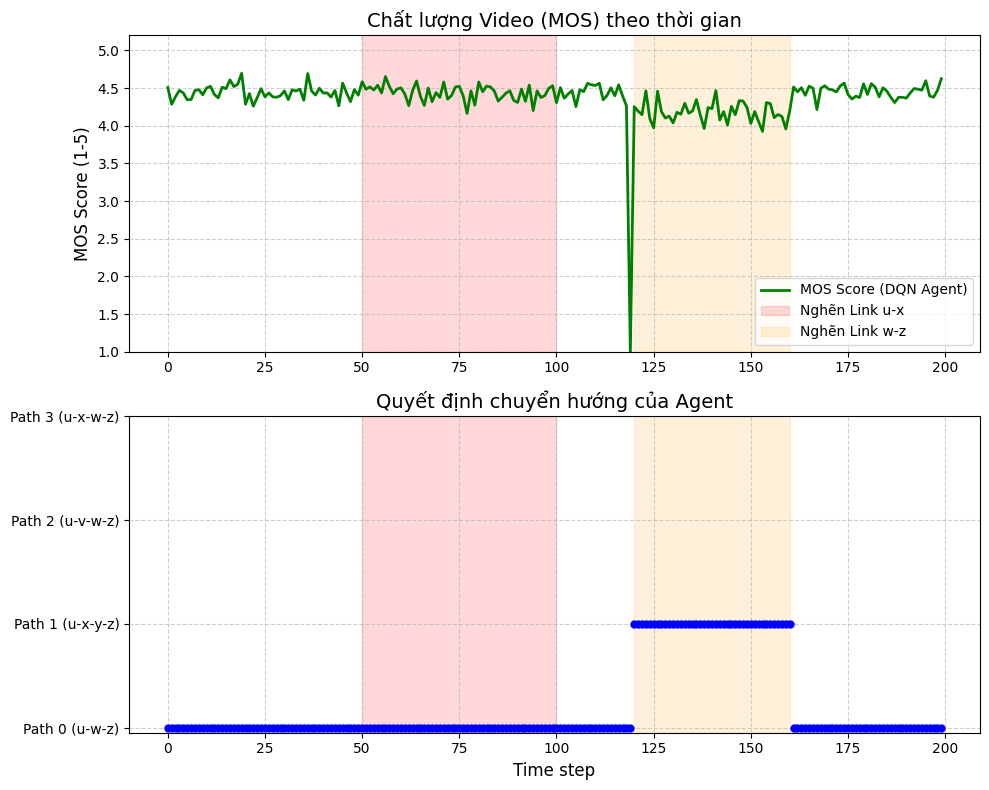

In [4]:
import torch # Thêm thư viện này để trích xuất Q-value từ Mạng Neural
import matplotlib.pyplot as plt

# Chạy đánh giá Agent sau khi học
obs, info = env.reset()

mos_history =[]
action_history =[]

print("="*60)
print("BẮT ĐẦU CHẠY THỰC TẾ (DEMO QUÁ TRÌNH SUY NGHĨ CỦA AGENT)")
print("="*60)

for i in range(200):
    # 1. TRÍCH XUẤT Q-VALUE TỪ MẠNG NEURAL CỦA DQN
    # Chuyển observation thành tensor để đưa vào mạng Neural
    obs_tensor = torch.tensor(obs).reshape(1, -1) 
    # Lấy giá trị Q-values từ mạng q_net của mô hình
    q_values = model.q_net(obs_tensor).detach().numpy()[0]
    
    # 2. AGENT RA QUYẾT ĐỊNH (Chọn hành động có Q-value cao nhất)
    action, _states = model.predict(obs, deterministic=True)
    action = int(action)
    
    # 3. MÔI TRƯỜNG PHẢN HỒI
    obs, reward, terminated, truncated, info = env.step(action)
    
    mos_history.append(info['mos_score'])
    action_history.append(action)
    
    # 4. IN LOG RA MÀN HÌNH (Chỉ in một số bước đại diện để tránh trôi màn hình)
    # In 3 bước đầu tiên, vài bước lúc nghẽn link u-x, và vài bước lúc nghẽn link w-z
    if i < 3 or (50 <= i <= 52) or (120 <= i <= 122):
        # Trích xuất Delay của link u-x (index 2 -> vị trí số 4) và link w-z (index 8 -> vị trí số 16)
        delay_ux = obs[4]
        delay_wz = obs[16]
        
        print(f"\n[Bước {i+1}]")
        print(f" - Trạng thái mạng : Delay u-x = {delay_ux:.1f}ms | Delay w-z = {delay_wz:.1f}ms")
        print(f" - AI tính Q-Values: Path 0: {q_values[0]:.2f} | Path 1: {q_values[1]:.2f} | Path 2: {q_values[2]:.2f} | Path 3: {q_values[3]:.2f}")
        print(f" - Quyết định      : Agent CHỌN PATH {action} -> Nhận Phần thưởng (MOS) = {reward:.2f}")

print("\n" + "="*60)
print("KẾT THÚC DEMO - ĐANG VẼ BIỂU ĐỒ...")
print("="*60)

# ==========================================
# CODE VẼ BIỂU ĐỒ (Giữ nguyên như cũ)
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={'height_ratios':[1, 1]})

ax1.plot(mos_history, color='green', linewidth=2, label='MOS Score (DQN Agent)')
ax1.axvspan(50, 100, color='red', alpha=0.15, label='Nghẽn Link u-x')
ax1.axvspan(120, 160, color='orange', alpha=0.15, label='Nghẽn Link w-z')
ax1.set_title("Chất lượng Video (MOS) theo thời gian", fontsize=14)
ax1.set_ylabel("MOS Score (1-5)", fontsize=12)
ax1.set_ylim(1.0, 5.2)
ax1.legend(loc="lower right")
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(action_history, color='blue', marker='o', linestyle='None', markersize=5)
ax2.axvspan(50, 100, color='red', alpha=0.15)
ax2.axvspan(120, 160, color='orange', alpha=0.15)
y_labels =['Path 0 (u-w-z)', 'Path 1 (u-x-y-z)', 'Path 2 (u-v-w-z)', 'Path 3 (u-x-w-z)']
ax2.set_yticks([0, 1, 2, 3])
ax2.set_yticklabels(y_labels)
ax2.set_title("Quyết định chuyển hướng của Agent", fontsize=14)
ax2.set_xlabel("Time step", fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [5]:
model.save("dqn_model_final")

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import DQN

# 1. TẢI LẠI MÔI TRƯỜNG VÀ MODEL (Đảm bảo bạn đã chạy Cell tạo Env trước đó)
env = BandwidthVideoRoutingEnv()
model = DQN.load("dqn_model_bandwidth")

# 2. ĐỊNH NGHĨA CÁC THUẬT TOÁN (POLICIES)
def greedy_policy():
    return 1  # Luôn chọn Path 1 (Đường ngắn nhất mặc định, bất chấp kẹt xe)

def random_policy():
    return np.random.randint(0, 4) # Chọn bừa 1 trong 4 đường

# Khởi tạo các mảng lưu trữ số liệu (Metrics)
steps = 200
metrics = {
    "RL": {"reward": [], "delay": [], "throughput": [], "cumulative_reward":[0]},
    "Greedy": {"reward": [], "delay": [], "throughput":[], "cumulative_reward": [0]},
    "Random": {"reward": [], "delay": [], "throughput":[], "cumulative_reward": [0]}
}

# 3. CHẠY THỰC NGHIỆM ĐÁNH GIÁ (EVALUATION LOOP)
for policy_name in ["RL", "Greedy", "Random"]:
    obs, _ = env.reset()
    cum_reward = 0
    
    for step in range(steps):
        # Chọn Action theo từng loại thuật toán
        if policy_name == "RL":
            action, _ = model.predict(obs, deterministic=True)
            action = int(action)
        elif policy_name == "Greedy":
            action = greedy_policy()
        else:
            action = random_policy()
            
        # Môi trường phản hồi
        obs, reward, _, _, _ = env.step(action)
        
        # Mô phỏng quy đổi sang Delay và Throughput để vẽ biểu đồ
        # Băng thông của đường được chọn càng cao (nghẽn) -> Delay càng cao, Throughput video càng thấp
        chosen_path_bandwidth = 10.0 - reward # Từ công thức Reward = 10 - BW
        
        simulated_delay = chosen_path_bandwidth * 20.0 # Map Băng thông sang Độ trễ (ms)
        simulated_throughput = max(0.5, 10.0 - chosen_path_bandwidth) # Băng thông còn lại cho Video (Mbps)
        
        cum_reward += reward
        
        # Lưu số liệu
        metrics[policy_name]["reward"].append(reward)
        metrics[policy_name]["cumulative_reward"].append(cum_reward)
        metrics[policy_name]["delay"].append(simulated_delay)
        metrics[policy_name]["throughput"].append(simulated_throughput)

# 4. TRỰC QUAN HÓA KẾT QUẢ (VISUALIZATION) bằng Matplotlib
plt.style.use('seaborn-v0_8-whitegrid') # Style biểu đồ học thuật
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

# Vẽ vùng tắc nghẽn (Từ step 50 đến 150)
for ax in axs:
    ax.axvspan(50, 150, color='red', alpha=0.1, label='Congestion Period (Tắc nghẽn)')

# --- Biểu đồ 1: Performance Comparison (Delay) ---
axs[0].plot(metrics["RL"]["delay"], label="DQN Agent", color='green', linewidth=2)
axs[0].plot(metrics["Greedy"]["delay"], label="Greedy (OSPF/STP)", color='red', linestyle='--')
axs[0].plot(metrics["Random"]["delay"], label="Random Policy", color='gray', alpha=0.5)
axs[0].set_title("So sánh Hiệu năng: Độ trễ Mạng (Delay Comparison)", fontsize=14, fontweight='bold')
axs[0].set_ylabel("Delay (ms)", fontsize=12)
axs[0].legend()

# --- Biểu đồ 2: Thông lượng mạng (Throughput) ---
axs[1].plot(metrics["RL"]["throughput"], label="DQN Agent", color='blue', linewidth=2)
axs[1].plot(metrics["Greedy"]["throughput"], label="Greedy (OSPF/STP)", color='red', linestyle='--')
axs[1].plot(metrics["Random"]["throughput"], label="Random Policy", color='gray', alpha=0.5)
axs[1].set_title("So sánh Hiệu năng: Thông lượng Video (Throughput Comparison)", fontsize=14, fontweight='bold')
axs[1].set_ylabel("Throughput (Mbps)", fontsize=12)
axs[1].legend()

# --- Biểu đồ 3: Cumulative Reward (Điểm thưởng tích lũy) ---
axs[2].plot(metrics["RL"]["cumulative_reward"], label="DQN Agent", color='purple', linewidth=2)
axs[2].plot(metrics["Greedy"]["cumulative_reward"], label="Greedy (OSPF/STP)", color='red', linestyle='--')
axs[2].plot(metrics["Random"]["cumulative_reward"], label="Random Policy", color='gray', alpha=0.5)
axs[2].set_title("Quá trình Hội tụ: Phần thưởng Tích lũy (Cumulative Reward)", fontsize=14, fontweight='bold')
axs[2].set_xlabel("Time Step", fontsize=12)
axs[2].set_ylabel("Total Reward", fontsize=12)
axs[2].legend()

plt.tight_layout()
plt.show()

# Lưu biểu đồ thành file ảnh chất lượng cao để chèn vào Word
fig.savefig("evaluation_metrics.png", dpi=300)
print("Đã lưu biểu đồ thành file evaluation_metrics.png!")

NameError: name 'BandwidthVideoRoutingEnv' is not defined